# 第 29 章：利率衍生品的标准市场模型

本章每一个算例，全部重新算一遍，其中两幅图也由其背后的公式重新生成。每一个数字都与书里印出的数值并排打印，因此任何数字一旦偏离书中的值，都能一眼看出，而不会悄悄出错。

| 小节 | 复现的内容 | 例 |
|---|---|---|
| 1 | 布莱克模型下的欧式债券期权 | 29.1 |
| 2 | 换算报价的收益率波动率，以及省略换算的代价 | 29.2 |
| 3 | 上限单元：前置与后置 | 29.3、29.4 |
| 4 | 由平坦波动率自举分段波动率；重新生成图 29.2 | 29.5 |
| 5 | 平值互换期权、它的正态波动率与两种 delta | 29.6、29.7 |
| 6 | 互换期权为什么比覆盖同一组利率的上限期权便宜 | — |
| 7 | 用三个报价拟合 SABR，以及每个参数各管什么 | 29.8 |

这里的计算全部是确定性的，因此每一个数字都应当精确复现到正文所印的位数。唯一的一次拟合（第 7 节的 SABR）是求解出来的，而不是抄来的：笔记本从三个报价中重新解出本章的参数。

用 NumPy、SciPy 与 Matplotlib。

表头保留英文：中文字符在等宽终端里是双宽的，而 Python 的 `%-46s` 按字符数计。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import exp, log, pi, sqrt
from scipy.optimize import brentq, fsolve
from scipy.stats import norm

N, phi = norm.cdf, norm.pdf
BAD = []

# 本书的配色，取自 preamble.tex：主序列用 exampleframe，对照序列用 snapshotframe。
# 各序列同时以线型和颜色区分，因为本书以灰度印刷。
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """把算出来的值印在本章所印的值旁边。`tol` 是绝对误差。"""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-46s %12.6f   book %11.6f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


def black(F, K, total_vol, df=1.0, call=True):
    """布莱克公式（式 29.1），传入的是总波动率 sigma*sqrt(T)。

    传入总量而不是分别传入 sigma 与 T，是后置上限单元的需要：
    在那里，方差并不等于 sigma^2 乘以到定盘日的时间。"""
    d1 = (log(F / K) + 0.5 * total_vol ** 2) / total_vol
    d2 = d1 - total_vol
    if call:
        return df * (F * N(d1) - K * N(d2)), d1, d2
    return df * (K * N(-d2) - F * N(-d1)), d1, d2


def bachelier(F, K, sigma_n, T, df=1.0):
    """正态模型（式 29.18）：F 与 K 取任何正负号都有定义。"""
    s = sigma_n * sqrt(T)
    d = (F - K) / s
    return df * ((F - K) * N(d) + s * phi(d))

## 1. 欧式债券期权：例 29.1

把布莱克公式用到债券上，要把现金价格换成**远期**债券价格：扣除期权持有人收不到的票息，再把余下的部分推到到期日，$F_0 = (B_0 - I)/P(0,T)$。波动率随之是远期价格的波动率。

In [2]:
B0, K = 102.50, 100.0
P025, P075, P1 = 0.9901, 0.9704, 0.9608
SIG_BOND, T_BOND = 0.04, 1.0

I = 3 * P025 + 3 * P075                       # 到期前支付的票息
F0 = (B0 - I) / P1                            # eq. (29.4)
c, d1, d2 = black(F0, K, SIG_BOND * sqrt(T_BOND), P1)

show("PV of the coupons, I", I, 5.8815, 5e-5)
show("forward bond price F0", F0, 100.5605, 5e-5)
show("d1", d1, 0.15973, 5e-5)
show("d2", d2, 0.11973, 5e-5)
show("N(d1)", N(d1), 0.563452, 5e-7)
show("N(d2)", N(d2), 0.547650, 5e-7)
show("call value per 100 face", c, 1.822, 5e-4)
show("  chain from the printed numbers", 0.9608 * (100.5605 * 0.563452 - 100 * 0.547650), 1.822, 5e-4)
print()
wrong, _, _ = black(B0, K, SIG_BOND, P1)
print("若改用现金价格定价，这份看涨期权值 %.3f：等于为持有人"
      % wrong)
print("根本收不到的票息付了钱")

PV of the coupons, I                               5.881500   book    5.881500   ok
forward bond price F0                            100.560470   book  100.560500   ok
d1                                                 0.159726   book    0.159730   ok
d2                                                 0.119726   book    0.119730   ok
N(d1)                                              0.563452   book    0.563452   ok
N(d2)                                              0.547650   book    0.547650   ok
call value per 100 face                            1.821640   book    1.822000   ok
  chain from the printed numbers                   1.821691   book    1.822000   ok

若改用现金价格定价，这份看涨期权值 3.040：等于为持有人
根本收不到的票息付了钱


## 2. 换算报价的收益率波动率：例 29.2

债券期权以**收益率**波动率报价，而布莱克公式需要的是**价格**波动率。久期把一个换成另一个，$\sigma \approx D^{*} y_0 \sigma_y$，这里的换算系数 $D^{*} y_0$ 为 0.269。省掉这一步，期权价格会高出约三倍半。

In [3]:
D_MOD, Y0, SIG_Y = 6.4, 0.042, 0.16
F_B, K_B, T_B, P_B = 98.50, 98.00, 2.0, 0.9124

sig_price = D_MOD * Y0 * SIG_Y                # eq. (29.5)
total = sig_price * sqrt(T_B)
c, d1, d2 = black(F_B, K_B, total, P_B)
wrong, _, _ = black(F_B, K_B, SIG_Y * sqrt(T_B), P_B)

show("price volatility, %", 100 * sig_price, 4.3008, 5e-5)
show("total volatility to expiration", total, 0.06082, 5e-6)
show("d1", d1, 0.11408, 5e-5)
show("d2", d2, 0.05326, 5e-5)
show("call value", c, 2.41, 5e-3)
show("call with 16% used as a price volatility", wrong, 8.31, 5e-3)
show("ratio of the wrong value to the right one", wrong / c, 3.45, 5e-3)
show("conversion factor D* y0", D_MOD * Y0, 0.269, 5e-4)

price volatility, %                                4.300800   book    4.300800   ok
total volatility to expiration                     0.060822   book    0.060820   ok
d1                                                 0.114082   book    0.114080   ok
d2                                                 0.053260   book    0.053260   ok
call value                                         2.410535   book    2.410000   ok
call with 16% used as a price volatility           8.305034   book    8.310000   ok
ratio of the wrong value to the right one          3.445307   book    3.450000   ok
conversion factor D* y0                            0.268800   book    0.269000   ok


## 3. 上限单元：前置与后置（例 29.3 与例 29.4）

前置利率在计息期开始时定盘，因此它的上限单元在 $T_1$ 就不再累积不确定性。复利计算的隔夜利率则一直变动到 $T_2$，其敏感度随着定盘值被逐日锁定而线性衰减，这额外增加了相当于 $\tau/3$ 年的方差：用 $\sigma^2(T_1 + \tau/3)$ 代替 $\sigma^2 T_1$。后置上限单元更值钱，这里高出 5.9%。

下图显示这一点在什么情况下重要。对于几年后才定盘的上限单元，增幅可以忽略；越靠前，增幅越大。对于**即期起始上限期权的第一个上限单元**（$T_1 = 0$），前置版本已经没有任何期权性，而后置版本仍有 $\sigma^2\tau/3$ 的方差。因此，把第一个上限单元排除在报价之外的旧惯例如今会低估价格。

forward-looking: d1                               -0.203123   book   -0.203100   ok
forward-looking: d2                               -0.403123   book   -0.403100   ok
forward-looking: N(d1)                             0.419519   book    0.419520   ok
forward-looking: N(d2)                             0.343429   book    0.343430   ok
forward-looking caplet, $                       5200.421136   book 5200.000000   ok

backward-looking: sigma^2 (T1 + tau/3)             0.043333   book    0.043333   ok
backward-looking: effective total vol              0.208167   book    0.208170   ok
backward-looking: d1                              -0.187148   book   -0.187100   ok
backward-looking: d2                              -0.395315   book   -0.395300   ok
backward-looking: N(d1)                            0.425772   book    0.425772   ok
backward-looking: N(d2)                            0.346305   book    0.346305   ok
backward-looking caplet, $                      5504.735231   book 5505.000

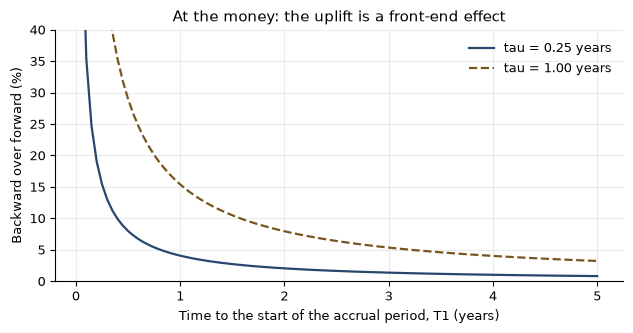

即期起始上限期权的第一个上限单元，平值，每单位名义本金：
  前置  0.000000  （利率已经定盘）
  后置  0.000230  （还有 sigma^2 tau/3 的方差未到）


In [4]:
L, TAU, F, KC, SIG, T1 = 10e6, 0.25, 0.04, 0.0425, 0.20, 1.0
P125 = 0.9520


def caplet(F, K, sig, T1, tau, df, backward=False, L=L):
    """式 (29.7)；后置利率累积的方差为 sigma^2 (T1 + tau/3)，式 (29.10)。"""
    var = sig ** 2 * (T1 + tau / 3.0) if backward else sig ** 2 * T1
    if var == 0.0:
        return L * tau * df * max(F - K, 0.0), None, None
    return (L * tau * df * black(F, K, sqrt(var), 1.0)[0],) + black(F, K, sqrt(var), 1.0)[1:]


fwd, d1, d2 = caplet(F, KC, SIG, T1, TAU, P125)
show("forward-looking: d1", d1, -0.2031, 5e-5)
show("forward-looking: d2", d2, -0.4031, 5e-5)
show("forward-looking: N(d1)", N(d1), 0.41952, 5e-6)
show("forward-looking: N(d2)", N(d2), 0.34343, 5e-6)
show("forward-looking caplet, $", fwd, 5200.0, 5.0)
print()
bwd, d1, d2 = caplet(F, KC, SIG, T1, TAU, P125, backward=True)
show("backward-looking: sigma^2 (T1 + tau/3)", SIG ** 2 * (T1 + TAU / 3), 0.043333, 5e-6)
show("backward-looking: effective total vol", sqrt(SIG ** 2 * (T1 + TAU / 3)), 0.20817, 5e-5)
show("backward-looking: d1", d1, -0.1871, 5e-5)
show("backward-looking: d2", d2, -0.3953, 5e-5)
show("backward-looking: N(d1)", N(d1), 0.425772, 5e-7)
show("backward-looking: N(d2)", N(d2), 0.346305, 5e-7)
show("backward-looking caplet, $", bwd, 5505.0, 5.0)
show("uplift, %", 100 * (bwd / fwd - 1), 5.9, 0.05)

# 把同一个上限单元沿曲线移动；取平值，使第一个上限单元不至于平凡地为零
fix = np.linspace(0.0, 5.0, 101)
fig, ax = plt.subplots()
for tau, ls, col in ((0.25, "-", BLUE), (1.0, "--", AMBER)):
    up = []
    for t in fix:
        f_ = caplet(F, F, SIG, t, tau, 1.0)[0]
        b_ = caplet(F, F, SIG, t, tau, 1.0, backward=True)[0]
        up.append(100 * (b_ / f_ - 1) if f_ > 0 else np.nan)
    ax.plot(fix, up, ls, color=col, lw=1.6, label="tau = %.2f years" % tau)
ax.set_xlabel("Time to the start of the accrual period, T1 (years)")
ax.set_ylabel("Backward over forward (%)")
ax.set_ylim(0, 40)
ax.set_title("At the money: the uplift is a front-end effect")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

first = caplet(F, F, SIG, 0.0, TAU, 1.0, backward=True, L=1.0)[0]
print("即期起始上限期权的第一个上限单元，平值，每单位名义本金：")
print("  前置  %.6f  （利率已经定盘）" % caplet(F, F, SIG, 0.0, TAU, 1.0, L=1.0)[0])
print("  后置  %.6f  （还有 sigma^2 tau/3 的方差未到）" % first)

## 4. 平坦波动率与分段波动率：例 29.5 与图 29.2

平坦波动率是一种报价手段：用一个数字为整份上限期权重新定价。分段波动率则属于某一个上限单元。自举逐个期限剥离上限单元，与由平价利率自举零息曲线完全平行。第二个上限单元自身的波动率为 21.7%，高于三年期上限期权 21% 的报价，因为那个报价被排在它前面、波动率较低的上限单元摊薄了。

下图把这个映射反过来做：从本章的分段波动率曲线出发，算出每一份上限期权应报的平坦波动率，再与本章所画的虚线比较。平坦曲线的峰值出现得更晚、更低，衰减得也更慢。它是到期日以前所有上限单元的平均。

In [5]:
KB, P2, P3 = 0.04, 0.9246, 0.8890
F12, F23 = 0.04, 0.043

two_year, _, _ = black(F12, KB, 0.20 * sqrt(1.0), P2)          # 只有一个上限单元，因此平坦 = 分段
a1, _, _ = black(F12, KB, 0.21 * sqrt(1.0), P2)                # 两个上限单元都用 21% 的平坦波动率
a2, _, _ = black(F23, KB, 0.21 * sqrt(2.0), P3)
residual = (a1 + a2) - two_year                                # [2,3] 上限单元必须值多少
sigma2 = brentq(lambda s: black(F23, KB, s * sqrt(2.0), P3)[0] - residual, 0.01, 1.0)

show("[1,2] caplet at 20%", two_year, 0.0029460, 5e-8)
show("  N(0.1), six decimals", N(0.1), 0.539828, 5e-7)
show("  N(-0.1), six decimals", N(-0.1), 0.460172, 5e-7)
show("[1,2] caplet at 21%", a1, 0.0030928, 5e-8)
show("[2,3] caplet at 21%", a2, 0.0058161, 5e-8)
show("three-year cap", a1 + a2, 0.0089089, 5e-8)
show("residual for the [2,3] caplet", residual, 0.0059629, 5e-8)
show("bootstrapped spot volatility, %", 100 * sigma2, 21.7, 0.05)
at21, _, _ = black(F23, KB, 0.21 * sqrt(2.0), P3)
show("[2,3] caplet understated at 21%, %", 100 * (1 - at21 / residual), 2.5, 0.1)

[1,2] caplet at 20%                                0.002946   book    0.002946   ok
  N(0.1), six decimals                             0.539828   book    0.539828   ok
  N(-0.1), six decimals                            0.460172   book    0.460172   ok
[1,2] caplet at 21%                                0.003093   book    0.003093   ok
[2,3] caplet at 21%                                0.005816   book    0.005816   ok
three-year cap                                     0.008909   book    0.008909   ok
residual for the [2,3] caplet                      0.005963   book    0.005963   ok
bootstrapped spot volatility, %                   21.734430   book   21.700000   ok
[2,3] caplet understated at 21%, %                 2.461422   book    2.500000   ok


worst gap to the plotted flat curve, vol pts       0.004871   book    0.000000   ok


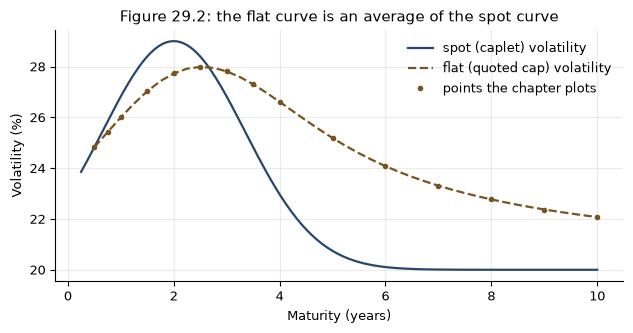

In [6]:
# 图 29.2：分段曲线取本章的 20 + 9 exp(-((x - 2)/1.9)^2)；每个平坦波动率在 4% 的平坦曲线上
# 为一份按季平值上限期权重新定价，排除第一个上限单元，每个上限单元的分段波动率按其支付日读取。
TAU_Q, FWD = 0.25, 0.04


def spot_vol(x):
    return (20.0 + 9.0 * np.exp(-((x - 2.0) / 1.9) ** 2)) / 100.0


def df_q(t):
    return (1.0 + FWD * TAU_Q) ** (-t / TAU_Q)


def flat_vol(M):
    ends = [TAU_Q * i for i in range(2, int(round(M / TAU_Q)) + 1)]
    price = lambda vol_of: sum(df_q(e) * black(FWD, FWD, vol_of(e) * sqrt(e - TAU_Q))[0]
                               for e in ends)
    target = price(spot_vol)
    return brentq(lambda s: price(lambda e: s) - target, 0.01, 1.0)


PLOTTED = ((0.5, 24.83), (0.75, 25.42), (1, 26.00), (1.5, 27.03), (2, 27.73),
           (2.5, 27.99), (3, 27.81), (3.5, 27.30), (4, 26.61), (5, 25.19),
           (6, 24.08), (7, 23.31), (8, 22.77), (9, 22.37), (10, 22.07))
worst = max(abs(100 * flat_vol(M) - v) for M, v in PLOTTED)
show("worst gap to the plotted flat curve, vol pts", worst, 0.0, 5e-3)

grid = np.linspace(0.5, 10, 39)
fig, ax = plt.subplots()
xs = np.linspace(0.25, 10, 200)
ax.plot(xs, 100 * spot_vol(xs), "-", color=BLUE, lw=1.6, label="spot (caplet) volatility")
ax.plot(grid, [100 * flat_vol(M) for M in grid], "--", color=AMBER, lw=1.6,
        label="flat (quoted cap) volatility")
ax.plot([m for m, _ in PLOTTED], [v for _, v in PLOTTED], "o", color=AMBER, ms=3,
        label="points the chapter plots")
ax.set_xlabel("Maturity (years)"); ax.set_ylabel("Volatility (%)")
ax.set_title("Figure 29.2: the flat curve is an average of the spot curve")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. 互换期权、它的正态波动率与两种 delta：例 29.6 与例 29.7

以年金为计价单位，远期互换利率是一个鞅，因此布莱克公式适用，只是用 $A(0)$ 代替贴现因子。把同一个价格在正态（巴舍利耶）模型下重新表述，得到 79.3 个基点；经验法则 $\sigma_B F_0$ 给出 80 个基点。

两种惯例在价格上一致，在对冲上不一致。在同一个价格下，布莱克 delta 为 $N(d_1) = 0.588$，巴舍利耶 delta 为 $N(0) = 0.500$，因此对冲这份 1 亿美元期权所需的远期互换，按一种惯例是 5,880 万美元，按另一种是 5,000 万美元。下图显示这个差距随 $\sigma\sqrt{T}$ 增大，与本章 $\varphi(0)\,\sigma\sqrt{T}/2$ 的说法一致。

annuity A(0)                                       3.659073   book    3.659074   ok
d1 at the money                                    0.223607   book    0.223610   ok
payer swaption, $                              2589697.908111   book 2589700.000000   ok
payer as % of notional                             2.589698   book    2.590000   ok
receiver less payer at the money, $                0.000000   book    0.000000   ok

option value per unit of annuity                   0.007077   book    0.007078   ok
normal volatility, bp                             79.338304   book   79.300000   ok
at-the-money shortcut sigma_N sqrt(T/2pi), bp     79.338304   book   79.300000   ok
rule of thumb sigma_B F0, bp                      80.000000   book   80.000000   ok

Black delta N(d1)                                  0.588468   book    0.588000   ok
Bachelier delta N(0)                               0.500000   book    0.500000   ok
hedge notional under Black, $m                    58.846836   book   

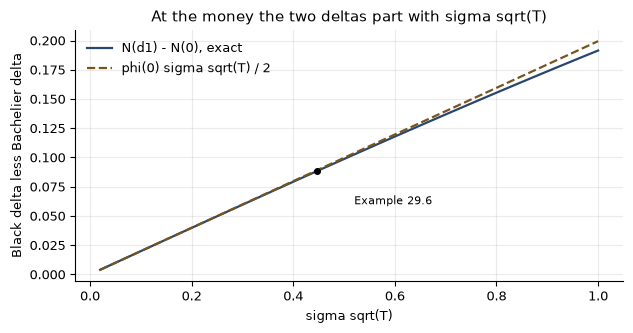

In [7]:
S0, KS, SIG_S, TS, LS = 0.04, 0.04, 0.20, 5.0, 100e6
dfs = [1.04 ** -i for i in range(6, 11)]       # 4% 的年付平坦曲线，第 6 至 10 年支付
A0 = sum(dfs)                                  # 式 (29.15)，按年计息

per_unit, d1, d2 = black(S0, KS, SIG_S * sqrt(TS))
payer = LS * A0 * per_unit                     # eq. (29.13)
receiver = LS * A0 * black(S0, KS, SIG_S * sqrt(TS), call=False)[0]
show("annuity A(0)", A0, 3.659074, 5e-6)
show("d1 at the money", d1, 0.22361, 5e-5)
show("payer swaption, $", payer, 2589700.0, 50.0)
show("payer as % of notional", 100 * payer / LS, 2.59, 5e-3)
show("receiver less payer at the money, $", receiver - payer, 0.0, 1e-6)
print()

# 例 29.7：给出同一价格的正态波动率
sig_n = brentq(lambda s: bachelier(S0, KS, s, TS) - per_unit, 1e-5, 0.05)
show("option value per unit of annuity", per_unit, 0.0070776, 5e-7)
show("normal volatility, bp", 1e4 * sig_n, 79.3, 0.05)
show("at-the-money shortcut sigma_N sqrt(T/2pi), bp",
     1e4 * per_unit / sqrt(TS / (2 * pi)), 79.3, 0.05)
show("rule of thumb sigma_B F0, bp", 1e4 * SIG_S * S0, 80.0, 1e-9)
print()

# 同一价格下的两种 delta
show("Black delta N(d1)", N(d1), 0.588, 5e-4)
show("Bachelier delta N(0)", N(0.0), 0.500, 1e-12)
show("hedge notional under Black, $m", LS * N(d1) / 1e6, 58.8, 0.05)
show("hedge notional under Bachelier, $m", LS * N(0.0) / 1e6, 50.0, 0.05)

total = np.linspace(0.02, 1.0, 50)             # sigma sqrt(T)
gap = N(0.5 * total) - 0.5                     # 平值时 d1 = sigma sqrt(T) / 2
fig, ax = plt.subplots()
ax.plot(total, gap, "-", color=BLUE, lw=1.6, label="N(d1) - N(0), exact")
ax.plot(total, phi(0) * total / 2, "--", color=AMBER, lw=1.6, label="phi(0) sigma sqrt(T) / 2")
ax.plot([SIG_S * sqrt(TS)], [N(d1) - 0.5], "o", color="black", ms=4)
ax.annotate("Example 29.6", xy=(SIG_S * sqrt(TS), N(d1) - 0.5), xytext=(0.52, 0.06), fontsize=8)
ax.set_xlabel("sigma sqrt(T)"); ax.set_ylabel("Black delta less Bachelier delta")
ax.set_title("At the money the two deltas part with sigma sqrt(T)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. 上限期权与互换期权：相关性的作用

上限期权是一组期权；互换期权是以一组利率为标的的一个期权。若 $n$ 个远期利率的波动率都是 $\sigma$，在互换利率中权重相等，两两相关系数都是 $\rho$，则互换利率的波动率为 $\sigma\sqrt{\rho + (1-\rho)/n}$。十个计息期、$\rho = 0.7$ 时，它是 $0.854\,\sigma$，比上限单元的波动率低约 15%，完全来自不完全相关。

反过来读，互换期权波动率与上限单元波动率之比，就是市场关于远期利率相关性的证据。因此第 32 章的模型要同时对两者校准，只对上限期权校准的模型则会把互换期权定错价。

ten periods, rho = 0.7                             0.854400   book    0.854000   ok
  so the swaption vol is lower by, %              14.559963   book   15.000000   ok


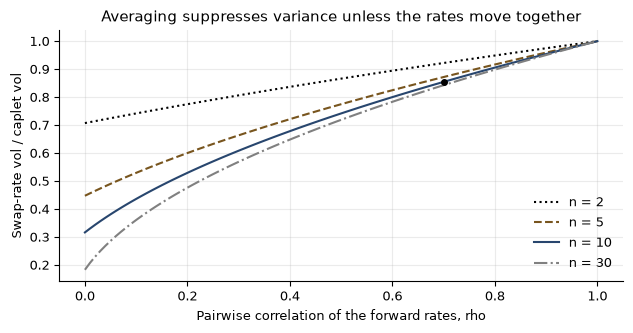

In [8]:
def swap_vol_ratio(rho, n):
    """n 个等权远期利率、相关系数均为 rho 时的 sigma_swap / sigma。"""
    return np.sqrt(rho + (1 - rho) / n)


show("ten periods, rho = 0.7", swap_vol_ratio(0.7, 10), 0.854, 5e-4)
show("  so the swaption vol is lower by, %", 100 * (1 - swap_vol_ratio(0.7, 10)), 15.0, 0.5)

rhos = np.linspace(0, 1, 101)
fig, ax = plt.subplots()
for n, ls, col in ((2, ":", "black"), (5, "--", AMBER), (10, "-", BLUE), (30, "-.", "gray")):
    ax.plot(rhos, swap_vol_ratio(rhos, n), ls, color=col, lw=1.5, label="n = %d" % n)
ax.plot([0.7], [swap_vol_ratio(0.7, 10)], "o", color="black", ms=4)
ax.set_xlabel("Pairwise correlation of the forward rates, rho")
ax.set_ylabel("Swap-rate vol / caplet vol")
ax.set_title("Averaging suppresses variance unless the rates move together")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 7. 对互换期权微笑拟合 SABR：例 29.8

本章的校准步骤，这里实际执行一遍，而不是照抄：

1. 固定 $\beta = 0.5$；
2. 对试探的 $\rho$ 与 $\nu$，由平值报价解出 $\alpha$，这是关于 $\alpha$ 的三次方程；
3. 调整 $\rho$ 与 $\nu$，直到两个翼部报价都被匹配，每一步都重新求解 $\alpha$，使平值报价始终成立。

按所印的报价求解，得到 $\rho = -0.29$、$\nu = 0.355$，与本章的 $\rho = -0.30$、$\nu = 0.35$ 略有出入。这并没有错。报价舍入到十分之一个波动率点，而本章的参数把三个报价都复现到这一位，因此这一带的任何参数都拟合得一样好。若从本章参数生成的、未经舍入的微笑出发求解，就能精确地解回这组参数。这同时度量了三个一位小数的报价对 $\rho$ 的约束有多松：0.05 个波动率点的舍入，就使它移动约 0.01。

随后的表格与微笑与本章一样，使用本章的参数。

                                alpha      rho       nu
from the printed quotes        0.0386   -0.291    0.355
from the unrounded smile       0.0387   -0.300    0.350
the chapter                    0.0387   -0.300    0.350



quoted fit: worst gap to the quotes, vol pts       0.000000   book    0.000000   ok
chapter fit: worst gap to the quotes, vol pts      0.042126   book    0.000000   ok
alpha, from the unrounded smile                    0.038700   book    0.038700   ok
rho, from the unrounded smile                     -0.300000   book   -0.300000   ok
nu, from the unrounded smile                       0.350000   book    0.350000   ok

leading term alpha / F^(1-beta)                    0.193500   book    0.193500   ok
C, first term                                     0.0003900
C, second term                                   -0.0025397
C, third term                                     0.0088302
C                                                  0.006681   book    0.006681   ok
K = 3%: z                                          0.484245   book    0.484200   ok
K = 3%: z / x(z)                                   1.099751   book    1.099800   ok
K = 3%: sigma_B, %                                23.595766   b

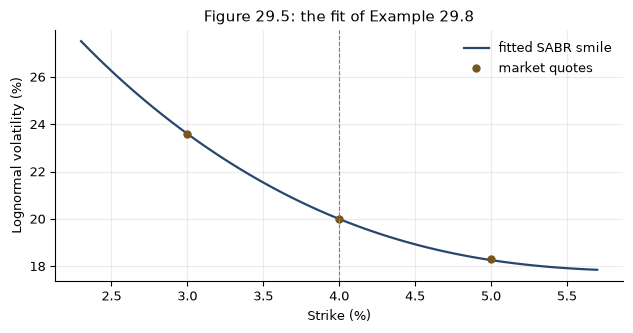

In [9]:
def hagan(K, F, T, alpha, beta, rho, nu):
    """Hagan 的对数正态隐含波动率，式 (29.22)。"""
    b = 1.0 - beta
    fk = (F * K) ** (b / 2.0)
    ell = log(F / K)
    D = 1.0 + b ** 2 / 24.0 * ell ** 2 + b ** 4 / 1920.0 * ell ** 4
    z = (nu / alpha) * fk * ell
    zx = 1.0 if abs(z) < 1e-12 else z / log((sqrt(1 - 2 * rho * z + z * z) + z - rho) / (1 - rho))
    C = (b ** 2 / 24.0 * alpha ** 2 / (F * K) ** b
         + 0.25 * rho * beta * nu * alpha / fk
         + (2.0 - 3.0 * rho ** 2) / 24.0 * nu ** 2)
    return alpha / (fk * D) * zx * (1.0 + C * T)


def alpha_from_atm(sig_atm, F, T, beta, rho, nu):
    """第 2 步：K = F 时，sigma_B = alpha F^(beta-1) (1 + C T) 是关于 alpha 的三次方程。"""
    b = 1.0 - beta
    coeffs = [b ** 2 / 24.0 / F ** (2 * b) * T / F ** b,
              0.25 * rho * beta * nu / F ** b * T / F ** b,
              (1.0 + (2.0 - 3.0 * rho ** 2) / 24.0 * nu ** 2 * T) / F ** b,
              -sig_atm]
    roots = [r.real for r in np.roots(coeffs) if abs(r.imag) < 1e-12 and r.real > 0]
    return min(roots)


F_S, T_S, BETA = 0.04, 5.0, 0.5
QUOTES = {0.03: 0.236, 0.04: 0.200, 0.05: 0.183}
ALPHA, RHO, NU = 0.0387, -0.30, 0.35           # 本章的拟合结果


def calibrate(quotes):
    """第 2、3 步：alpha 由平值报价确定，rho 与 nu 由两翼确定。"""
    def wing_errors(p):
        a = alpha_from_atm(quotes[0.04], F_S, T_S, BETA, *p)
        return [hagan(K, F_S, T_S, a, BETA, *p) - quotes[K] for K in (0.03, 0.05)]
    rho, nu = fsolve(wing_errors, [-0.2, 0.3], xtol=1e-12)
    return alpha_from_atm(quotes[0.04], F_S, T_S, BETA, rho, nu), rho, nu


print("%-28s %8s %8s %8s" % ("", "alpha", "rho", "nu"))
print("%-28s %8.4f %8.3f %8.3f" % (("from the printed quotes",) + calibrate(QUOTES)))
exact = {K: hagan(K, F_S, T_S, ALPHA, BETA, RHO, NU) for K in QUOTES}
print("%-28s %8.4f %8.3f %8.3f" % (("from the unrounded smile",) + calibrate(exact)))
print("%-28s %8.4f %8.3f %8.3f" % ("the chapter", ALPHA, RHO, NU))
print()
a_q, r_q, n_q = calibrate(QUOTES)
show("quoted fit: worst gap to the quotes, vol pts",
     max(abs(100 * (hagan(K, F_S, T_S, a_q, BETA, r_q, n_q) - v)) for K, v in QUOTES.items()), 0.0, 1e-6)
show("chapter fit: worst gap to the quotes, vol pts",
     max(abs(100 * (exact[K] - v)) for K, v in QUOTES.items()), 0.0, 0.05)
a_x, r_x, n_x = calibrate(exact)
show("alpha, from the unrounded smile", a_x, ALPHA, 1e-8)
show("rho, from the unrounded smile", r_x, RHO, 1e-6)
show("nu, from the unrounded smile", n_x, NU, 1e-6)
print()

b = 1 - BETA
show("leading term alpha / F^(1-beta)", ALPHA / F_S ** b, 0.1935, 5e-5)
C1 = b ** 2 / 24 * ALPHA ** 2 / F_S ** (2 * b)
C2 = 0.25 * RHO * BETA * NU * ALPHA / F_S ** b
C3 = (2 - 3 * RHO ** 2) / 24 * NU ** 2
for lbl, v in (("C, first term", C1), ("C, second term", C2), ("C, third term", C3)):
    print("%-46s %12.7f" % (lbl, v))
show("C", C1 + C2 + C3, 0.006681, 5e-6)
for K, zp, zxp, sp in ((0.03, 0.4842, 1.0998, 23.60), (0.05, -0.4268, 0.9655, 18.26)):
    z = NU / ALPHA * (F_S * K) ** (b / 2) * log(F_S / K)
    x = log((sqrt(1 - 2 * RHO * z + z * z) + z - RHO) / (1 - RHO))
    show("K = %.0f%%: z" % (100 * K), z, zp, 6e-5)
    show("K = %.0f%%: z / x(z)" % (100 * K), z / x, zxp, 6e-5)
    show("K = %.0f%%: sigma_B, %%" % (100 * K), 100 * hagan(K, F_S, T_S, ALPHA, BETA, RHO, NU), sp, 0.0051)
print()

STRIKES = (0.025, 0.030, 0.035, 0.040, 0.045, 0.050, 0.055)
TABLE = (26.25, 23.60, 21.54, 20.00, 18.92, 18.26, 17.91)
for K, v in zip(STRIKES, TABLE):
    show("sigma_B(%.1f%%), %%" % (100 * K), 100 * hagan(K, F_S, T_S, ALPHA, BETA, RHO, NU), v, 0.0051)

ks = np.linspace(0.023, 0.057, 120)
fig, ax = plt.subplots()
ax.plot(100 * ks, [100 * hagan(k, F_S, T_S, ALPHA, BETA, RHO, NU) for k in ks], "-",
        color=BLUE, lw=1.6, label="fitted SABR smile")
ax.plot([100 * k for k in QUOTES], [100 * v for v in QUOTES.values()], "o", color=AMBER,
        ms=5, label="market quotes")
ax.axvline(100 * F_S, color="gray", ls="--", lw=0.8)
ax.set_xlabel("Strike (%)"); ax.set_ylabel("Lognormal volatility (%)")
ax.set_title("Figure 29.5: the fit of Example 29.8")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 每个参数各管什么

每次都重新求解 $\alpha$，使平值波动率保持在 20%，然后一次只动一个参数。$\rho$ 使微笑倾斜：利率与波动率之间的相关性越负，向下的斜率越陡。$\nu$ 使微笑弯曲：波动率的波动率越高，两翼相对于穿过中间的直线抬得越高。正是这种分工（水平、偏斜、曲率），使得在固定 $\beta$ 之后，三个报价就能确定三个参数。

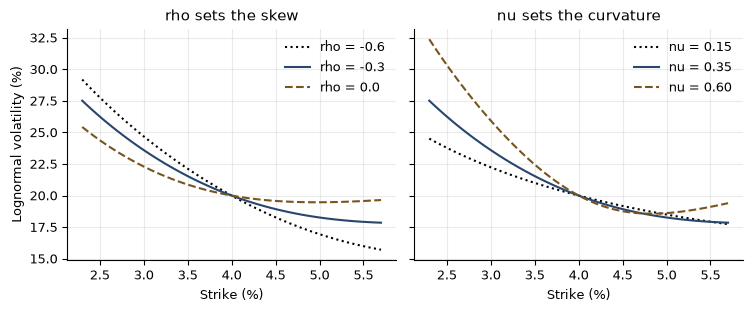

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.6, 3.2), sharey=True)
for rho, ls, col in ((-0.6, ":", "black"), (-0.3, "-", BLUE), (0.0, "--", AMBER)):
    a = alpha_from_atm(0.20, F_S, T_S, BETA, rho, NU)
    ax1.plot(100 * ks, [100 * hagan(k, F_S, T_S, a, BETA, rho, NU) for k in ks], ls,
             color=col, lw=1.5, label="rho = %.1f" % rho)
for nu, ls, col in ((0.15, ":", "black"), (0.35, "-", BLUE), (0.60, "--", AMBER)):
    a = alpha_from_atm(0.20, F_S, T_S, BETA, RHO, nu)
    ax2.plot(100 * ks, [100 * hagan(k, F_S, T_S, a, BETA, RHO, nu) for k in ks], ls,
             color=col, lw=1.5, label="nu = %.2f" % nu)
ax1.set_title("rho sets the skew"); ax2.set_title("nu sets the curvature")
for ax in (ax1, ax2):
    ax.set_xlabel("Strike (%)"); ax.legend(frameon=False)
ax1.set_ylabel("Lognormal volatility (%)")
plt.tight_layout(); plt.show()

## 重算的结论与两点收获

若下面一格报告每个数字都一致，本笔记本就与本章一致。

有两个习惯值得养成。**先确定惯例，再比较数字**：收益率波动率不是价格波动率，平坦波动率不是分段波动率，布莱克波动率也不是正态波动率，上面每一种混淆的代价，从 2.5% 到三倍半不等。以及**在价格上一致的模型，在对冲上仍可能不一致**：布莱克与巴舍利耶给出的互换期权价格分毫不差，所需的远期互换却相差 880 万美元。

In [11]:
if BAD:
    print("有 %d 个数字与正文不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本笔记本中的每个数字都与正文一致")

本笔记本中的每个数字都与正文一致
